Analisis exploratorio de datos

Librerias

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
from sklearn.linear_model import LinearRegression

Carga de informacion

In [2]:
df = pd.read_csv("listings_clean.csv", parse_dates=["price_quote_checkin_date"])
print(f"Registros: {len(df):,}  |  Variables: {df.shape[1]}  |  Datos faltantes: {int(df.isna().sum().sum())}")
df.head(3)

Registros: 33,590  |  Variables: 64  |  Datos faltantes: 0


,id,price,log_price,island,neighbourhood,latitude,longitude,room_type,property_group,accommodates,...,am_dishwasher,am_tv,am_bbq,am_beach_waterfront,am_ocean_view,am_gym,am_elevator,am_self_checkin,am_workspace,am_patio_balcony
0,784020,848.33,6.743270,Maui,Lahaina,20.995184,-156.665009,Entire home/apt,House,8,...,1,1,1,1,0,0,0,1,1,1
1,461638,101.86,4.623599,Hawaii,South Hilo,19.721000,-155.084950,Private room,House,1,...,0,0,0,0,0,0,0,0,0,1
2,479121,265.00,5.579730,Hawaii,Puna,19.400310,-154.920430,Entire home/apt,House,6,...,0,1,1,1,1,0,0,0,0,1


creacion de caracteristicas de comparacion para el analisis
price_per_person: precio/capacidad
host_size:tamaño del operador
Rating:calificacion en bandas

In [3]:
df["price_per_person"] = df["price"] / df["accommodates"]
df["host_size"] = pd.cut(df["calculated_host_listings_count"], [0, 1, 5,50, np.inf],
labels=["1 anuncio", "2–5", "6–50", "más de 50"])
df["rating_band"] = pd.cut(df["review_scores_rating"], [0, 4.5, 4.7, 4.8, 4.9, 5.0],
labels=["< 4.5", "4.5–4.7", "4.7–4.8", "4.8–4.9", "4.9–5.0"], include_lowest=True)
amenidades = [c for c in df.columns if c.startswith("am_")]

Estadisticas descriptivas

In [5]:
numericas = ["price", "price_per_person", "accommodates", "bedrooms", "beds", "bathrooms", "minimum_nights",
             "availability_365", "estimated_occupancy_l365d", "host_years", "calculated_host_listings_count",
             "number_of_reviews", "reviews_per_month", "review_scores_rating", "review_scores_value", "n_amenities"]
desc = df[numericas].describe(percentiles=[.25, .5, .75]).T
desc["asimetría"] = df[numericas].skew()
desc["curtosis"] = df[numericas].kurt()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetría,curtosis
price,33590.0,495.15,377.42,67.72,257.12,375.50,594.00,2409.80,2.13,5.33
price_per_person,33590.0,106.95,64.88,7.16,64.58,91.00,130.67,1615.00,2.79,21.93
accommodates,33590.0,4.79,2.32,1.00,4.00,4.00,6.00,16.00,1.49,3.99
bedrooms,33590.0,1.54,1.02,0.00,1.00,1.00,2.00,5.00,0.79,0.90
beds,33590.0,2.61,1.40,1.00,2.00,2.00,3.00,8.00,1.26,2.12
bathrooms,33590.0,1.60,0.77,0.00,1.00,1.00,2.00,4.50,1.28,1.74
minimum_nights,33590.0,5.80,19.22,1.00,1.00,2.00,3.00,365.00,9.26,107.04
availability_365,33590.0,233.74,97.17,0.00,175.00,256.00,309.00,365.00,-0.72,-0.41
estimated_occupancy_l365d,33590.0,55.46,73.75,0.00,0.00,18.00,90.00,255.00,1.37,0.79
host_years,33590.0,6.91,3.86,0.00,3.92,6.92,10.17,15.67,0.03,-0.97


composicion

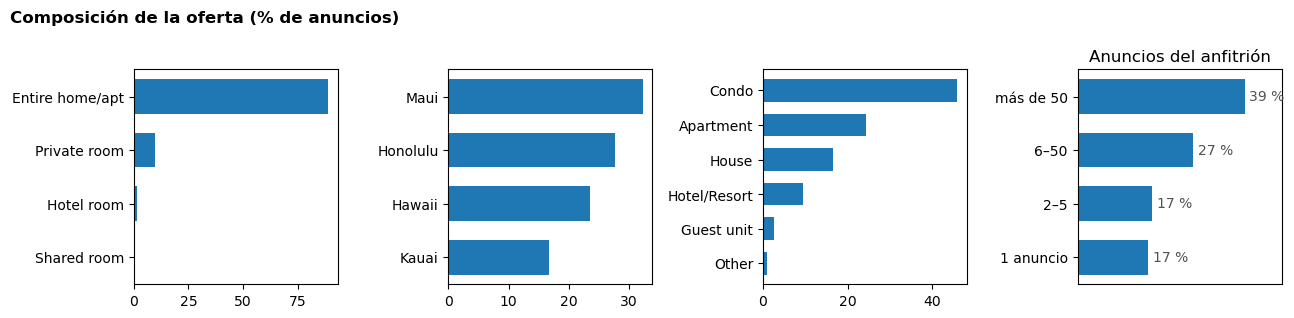

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, (c, titulo) in zip(axes, [("room_type", "Tipo de alojamiento"), ("island", "Isla"),("property_group", "Tipo de edificación"), ("host_size", "Anuncios del anfitrión")]):
    vc = (df[c].value_counts(normalize=True) * 100).sort_values()
    ax.barh(vc.index.astype(str), vc.values, height=0.65)
for y, v in enumerate(vc.values):
    ax.text(v + 1, y, f"{v:.0f} %", va="center", color="#52514e")
ax.set_title(titulo); ax.set_xlim(0, vc.max() * 1.22); ax.grid(False); ax.set_xticks([])
plt.suptitle("Composición de la oferta (% de anuncios)", x=0.01 ,ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

el 89% de los alojaminetos son completos, casio la mitad son condominios luegos aptos y casas.

el 39% pertenece a administradores de propiedades vs 17% a personas con un solo anuncio


Variable objetivo precio por noche

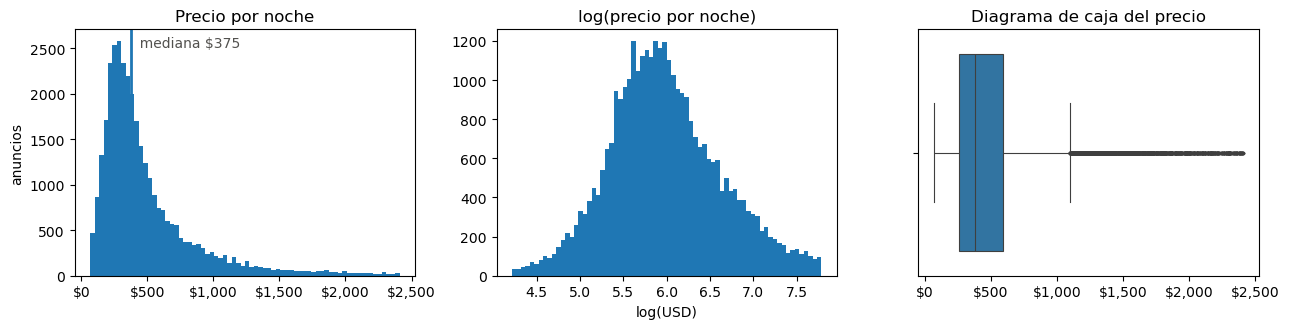

Media $495 | Mediana $375 | Rango intercuartílico $257–$594 | Asimetría precio 2.13 vs. log(precio) 0.28


In [20]:
usd = FuncFormatter(lambda v, _: f"${v:,.0f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].hist(df["price"], bins=70)
axes[0].axvline(df["price"].median(), lw=2)
axes[0].text(df["price"].median(), axes[0].get_ylim()[1] * 0.93, f"  mediana ${df['price'].median():,.0f}", color="#52514e")
axes[0].set_title("Precio por noche"); axes[0].xaxis.set_major_formatter(usd); axes[0].set_ylabel("anuncios")
axes[1].hist(df["log_price"], bins=70)
axes[1].set_title("log(precio por noche)"); axes[1].set_xlabel("log(USD)")
sns.boxplot(x=df["price"], ax=axes[2], fliersize=1.5, linewidth=0.8)
axes[2].set_title("Diagrama de caja del precio"); axes[2].xaxis.set_major_formatter(usd); axes[2].set_xlabel("")
plt.tight_layout()
plt.show()
print(f"Media ${df['price'].mean():,.0f} | Mediana ${df['price'].median():,.0f} | "
      f"Rango intercuartílico ${df['price'].quantile(.25):,.0f}–${df['price'].quantile(.75):,.0f} | "
      f"Asimetría precio {df['price'].skew():.2f} vs. log(precio) {df['log_price'].skew():.2f}")


el precio mediano por noche es de 375 USD por noche y la mitad de los anuncios esta en 257 - 594 la media 495 usd  

tien cola pesada a la derecha aplicamos logaritmo  y ya parece una normal

por lo que ahora nuetra variable es log (precios)


precio y ubicacion

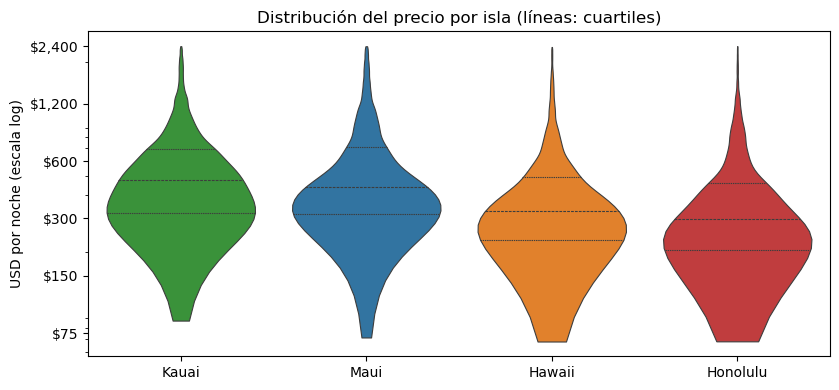

,count,25%,50%,75%
island,,,,
Kauai,5586.0,320.0,475.0,693.0
Maui,10830.0,315.0,437.0,709.0
Hawaii,7907.0,230.0,328.0,493.0
Honolulu,9267.0,204.0,297.0,463.0


In [ ]:
orden_islas = df.groupby("island")["price"].median().sort_values(ascending=False).index.tolist()
fig, ax = plt.subplots(figsize=(8.5, 4))
sns.violinplot(data=df, x="island", y="price", hue="island", order=orden_islas,inner="quartile", cut=0, linewidth=0.8, legend=False, ax=ax)
ax.set_yscale("log"); ax.yaxis.set_major_formatter(usd)
ax.set_yticks([75, 150, 300, 600, 1200, 2400])
ax.set_xlabel(""); ax.set_ylabel("USD por noche (escala log)")
ax.set_title("Distribución del precio por isla (líneas: cuartiles)")
plt.tight_layout()
plt.show()
df.groupby("island")["price"].describe()[["count", "25%", "50%", "75%"]].loc[orden_islas].round(0)

precio por zona

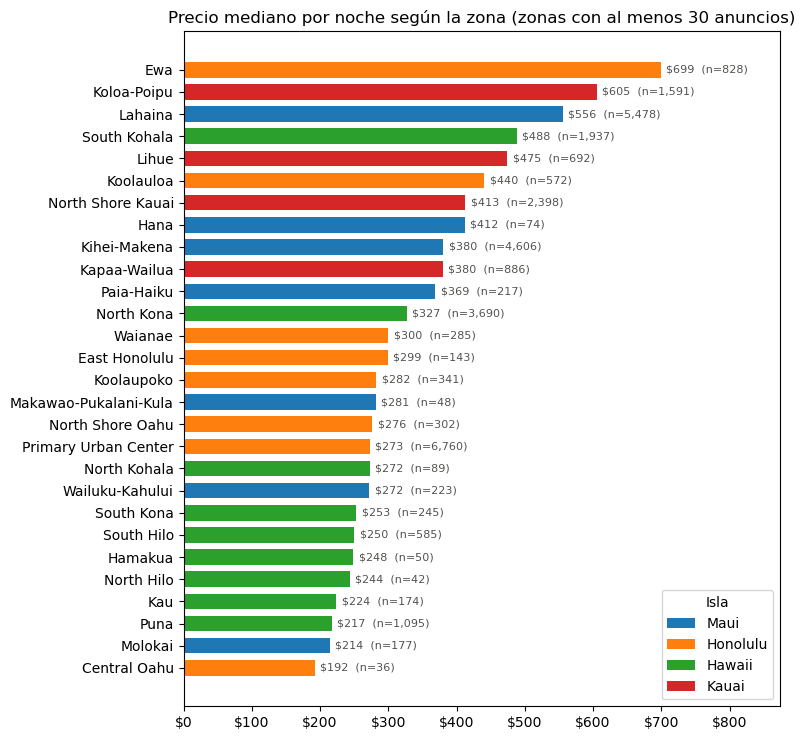

In [35]:
from matplotlib.patches import Patch

colores = {
    "Maui": "#1f77b4",
    "Honolulu": "#ff7f0e",
    "Hawaii": "#2ca02c",
    "Kauai": "#d62728",
}

zonas = df.groupby(["neighbourhood", "island"])["price"].agg(mediana="median", anuncios="size").reset_index()
zonas = zonas[zonas["anuncios"] >= 30].sort_values("mediana")
fig, ax = plt.subplots(figsize=(8, 7.5))
ax.barh(zonas["neighbourhood"], zonas["mediana"],color=zonas["island"].map(colores), height=0.7)
for y, (v, n) in enumerate(zip(zonas["mediana"], zonas["anuncios"])):
    ax.text(v + 8, y, f"${v:,.0f}  (n={n:,})", va="center", color="#52514e", fontsize=8)
ax.xaxis.set_major_formatter(usd); ax.set_xlim(0, zonas["mediana"].max() * 1.25)
ax.grid(axis="y", visible=False)
ax.set_title("Precio mediano por noche según la zona (zonas con al menos 30 anuncios)")
ax.legend(handles=[Patch(facecolor=c, label=isla) for isla, c in colores.items()], title="Isla", loc="lower right")
plt.tight_layout()
plt.show()

NOTA SUPER IMPORTANTE 

Mapra de calor de alojamientos y su distribucion 

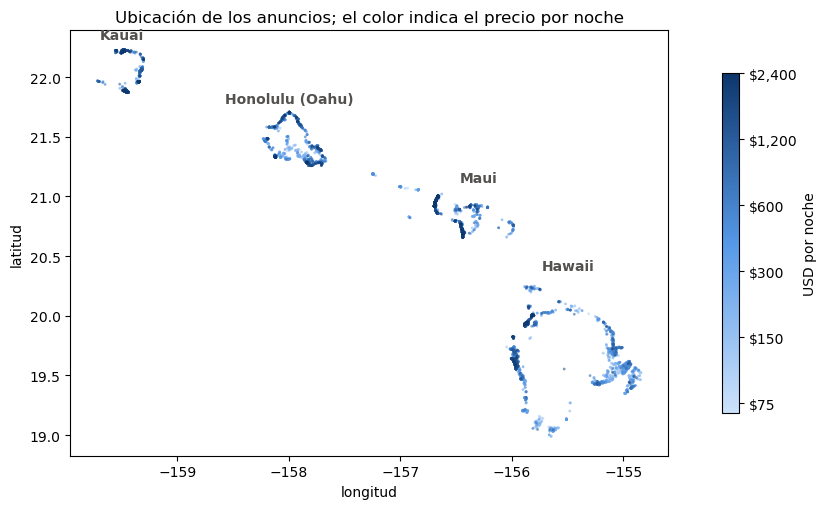

In [37]:
fig, ax = plt.subplots(figsize=(11, 5.2))
m = df.sort_values("price")
sc = ax.scatter(m["longitude"], m["latitude"], c=m["log_price"], cmap=LinearSegmentedColormap.from_list("azules", ["#cde2fb", "#5598e7", "#0d366b"]), s=4, alpha=0.6, linewidths=0)
cb = plt.colorbar(sc, ax=ax, shrink=0.8, ticks=np.log([75, 150, 300, 600, 1200, 2400]))
cb.solids.set_alpha(1)
cb.ax.set_yticklabels(["$75", "$150", "$300", "$600", "$1,200", "$2,400"]); cb.set_label("USD por noche")
for isla, (x, y) in {"Kauai": (-159.5, 22.32), "Honolulu (Oahu)": (-158.0, 21.78), "Maui": (-156.3, 21.12), "Hawaii": (-155.5, 20.38)}.items():
    ax.text(x, y, isla, ha="center", color="#52514e", fontweight="bold")
ax.set_aspect(1 / np.cos(np.radians(20.9))); ax.grid(False)
ax.set_xlabel("longitud"); ax.set_ylabel("latitud")
ax.set_title("Ubicación de los anuncios; el color indica el precio por noche")
plt.tight_layout()
plt.show()

Vemos una clara tendencia que los bordes de la isla son los mas apetecidos

Precios y caracteristicas por inmueble

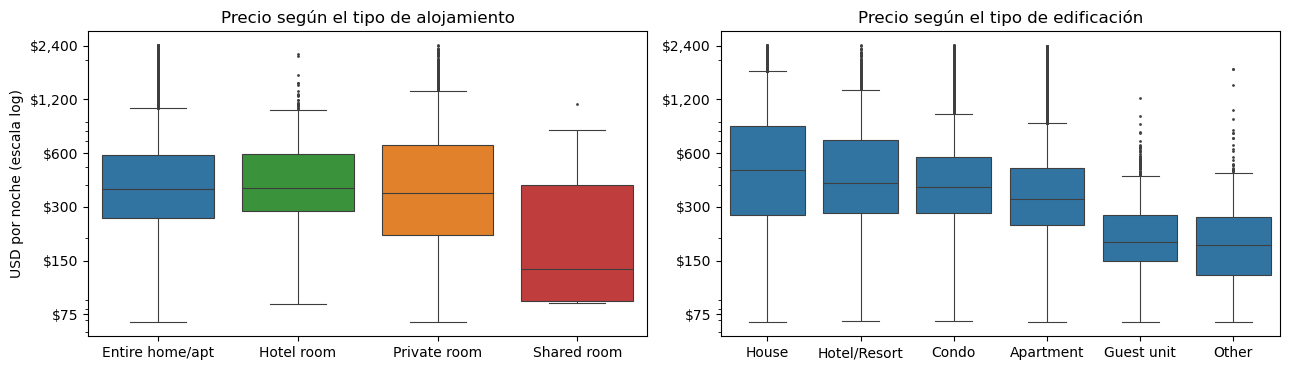

,count,25%,50%,75%
room_type,,,,
Entire home/apt,29855.0,260.0,377.0,588.0
Hotel room,492.0,285.0,381.0,597.0
Private room,3225.0,209.0,357.0,664.0
Shared room,18.0,89.0,136.0,396.0


In [41]:
colorestipo = {
    "Entire home/apt": "#1f77b4",
    "Private room": "#ff7f0e",
    "Hotel room": "#2ca02c",
    "Shared room": "#d62728",
}

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
orden_tipo = ["Entire home/apt", "Hotel room", "Private room", "Shared room"]
sns.boxplot(data=df, x="room_type", y="price", hue="room_type", order=orden_tipo, palette=colorestipo,
            fliersize=1, linewidth=0.8, legend=False, ax=axes[0])
axes[0].set_yscale("log"); axes[0].yaxis.set_major_formatter(usd); axes[0].set_yticks([75, 150, 300, 600, 1200, 2400])
axes[0].set_xlabel(""); axes[0].set_ylabel("USD por noche (escala log)"); axes[0].set_title("Precio según el tipo de alojamiento")
orden_prop = df.groupby("property_group")["price"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="property_group", y="price", order=orden_prop, fliersize=1, linewidth=0.8, ax=axes[1])
axes[1].set_yscale("log"); axes[1].yaxis.set_major_formatter(usd); axes[1].set_yticks([75, 150, 300, 600, 1200, 2400])
axes[1].set_xlabel(""); axes[1].set_ylabel(""); axes[1].set_title("Precio según el tipo de edificación")
plt.tight_layout()
plt.show()
df.groupby("room_type")["price"].describe()[["count", "25%", "50%", "75%"]].loc[orden_tipo].round(0)

Precios y caracterisircas de los inmubeles

In [42]:
cruce = df[df["room_type"].isin(["Entire home/apt", "Private room"])].pivot_table(
    index="property_group", columns="room_type", values="price", aggfunc=["median", "size"]).round(0)
cruce.columns = [f"{'mediana USD' if a == 'median' else 'anuncios'} · {b}" for a, b in cruce.columns]
cruce

,mediana USD · Entire home/apt,mediana USD · Private room,anuncios · Entire home/apt,anuncios · Private room
property_group,,,,
Apartment,332.0,217.0,8099,83
Condo,386.0,269.0,15352,87
Guest unit,195.0,184.0,739,99
Hotel/Resort,278.0,426.0,213,2494
House,512.0,149.0,5193,383
Other,193.0,171.0,259,79


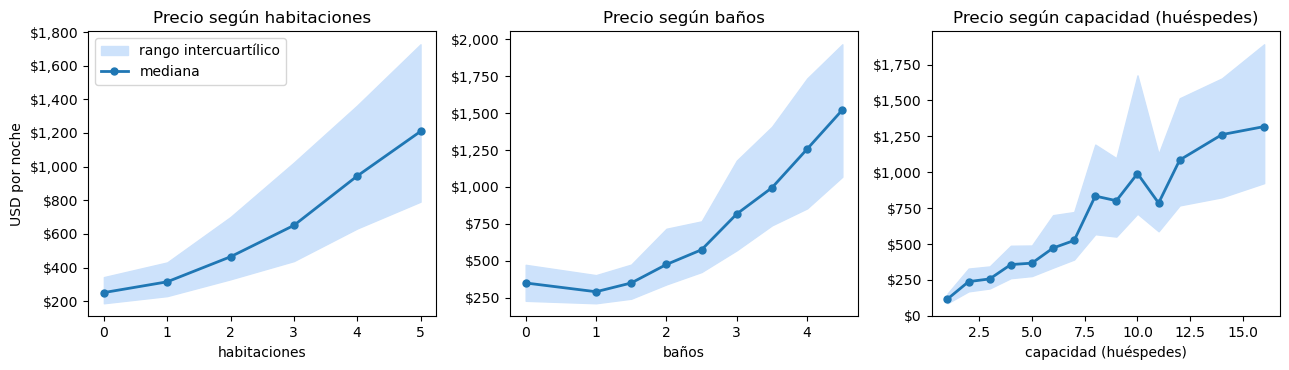

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, c, titulo in zip(axes, ["bedrooms", "bathrooms", "accommodates"], ["habitaciones", "baños", "capacidad (huéspedes)"]):
    g = df.groupby(c)["price"].agg(["median", "size", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
    g.columns = ["mediana", "n", "q1", "q3"]
    g = g[g["n"] >= 50]
    ax.fill_between(g.index, g["q1"], g["q3"], color="#cde2fb", label="rango intercuartílico")
    ax.plot(g.index, g["mediana"], lw=2, marker="o", ms=5, label="mediana")
    ax.yaxis.set_major_formatter(usd); ax.set_xlabel(titulo); ax.set_title(f"Precio según {titulo}")
axes[0].set_ylabel("USD por noche"); axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

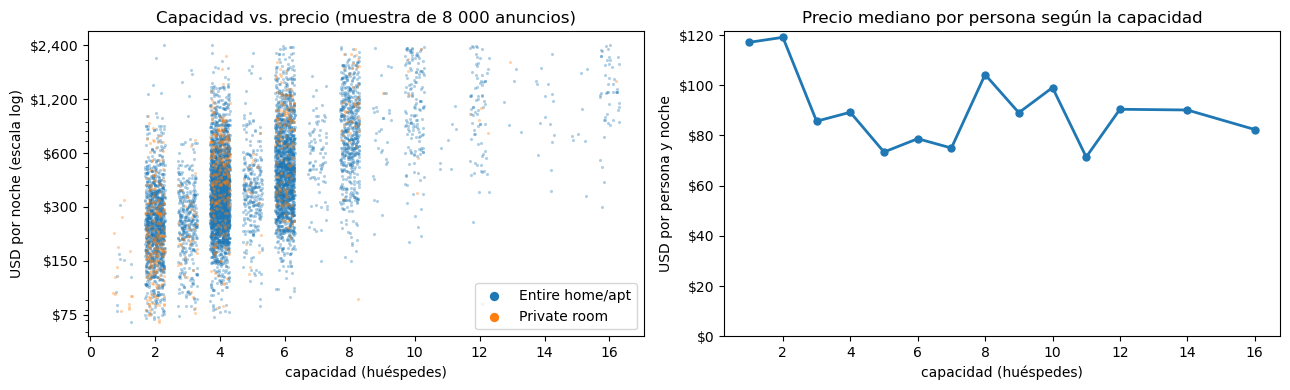

In [47]:
rng = np.random.default_rng(0)
muestra = df.sample(8000, random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for tipo in ["Entire home/apt", "Private room"]:
    s = muestra[muestra["room_type"] == tipo]
    axes[0].scatter(s["accommodates"] + rng.uniform(-0.3, 0.3, len(s)), s["price"], s=5, alpha=0.35, color=colorestipo[tipo], linewidths=0, label=tipo)
axes[0].set_yscale("log"); axes[0].yaxis.set_major_formatter(usd); axes[0].set_yticks([75, 150, 300, 600, 1200, 2400])
axes[0].set_xlabel("capacidad (huéspedes)"); axes[0].set_ylabel("USD por noche (escala log)")
axes[0].set_title("Capacidad vs. precio (muestra de 8 000 anuncios)")
leg = axes[0].legend(markerscale=3, loc="lower right")
for h in leg.legend_handles:
    h.set_alpha(1)

pp = df.groupby("accommodates")["price_per_person"].median()
pp = pp[df["accommodates"].value_counts().reindex(pp.index) >= 50]
axes[1].plot(pp.index, pp.values, lw=2, marker="o", ms=5)
axes[1].yaxis.set_major_formatter(usd); axes[1].set_ylim(0)
axes[1].set_xlabel("capacidad (huéspedes)"); axes[1].set_ylabel("USD por persona y noche")
axes[1].set_title("Precio mediano por persona según la capacidad")
plt.tight_layout()
plt.show()

observamos que el tamaño es el factor que mas mueve el precio,la mediana pasa de 251 estudio a 315 1 habitacion 464 2 habitaciones 650 3 habitaciones y mas de 1200 por 5 habitaciones


precio por persona baja con tamaño 

las casa y hoteles/resorts son los mas caros

Analisis de amenidades por vivienda

In [51]:
controles_num = ["accommodates", "bedrooms", "beds", "bathrooms", "bath_shared", "long_stay", "quote_nights", "quote_lead_days"]
X = pd.concat([df[controles_num], df[amenidades],
               pd.get_dummies(df[["room_type", "property_group", "neighbourhood"]], drop_first=True, dtype=int),
               pd.get_dummies(df["quote_checkin_month"], prefix="mes", drop_first=True, dtype=int)], axis=1)
reg = LinearRegression().fit(X, df["log_price"])
print(f"R² de la regresión de control: {reg.score(X, df['log_price']):.2f}")
coef = pd.Series(reg.coef_, index=X.columns)

tabla_am = pd.DataFrame({
    "% de anuncios": df[amenidades].mean() * 100,
    "mediana con": [df.loc[df[a] == 1, "price"].median() for a in amenidades],
    "mediana sin": [df.loc[df[a] == 0, "price"].median() for a in amenidades],
}, index=amenidades)
tabla_am["dif. bruta %"] = (tabla_am["mediana con"] / tabla_am["mediana sin"] - 1) * 100
tabla_am["dif. ajustada %"] = (np.exp(coef[amenidades]) - 1) * 100
tabla_am.index = tabla_am.index.str.replace("am_", "")
tabla_am = tabla_am.sort_values("dif. ajustada %")
tabla_am.round(1)

R² de la regresión de control: 0.62


,% de anuncios,mediana con,mediana sin,dif. bruta %,dif. ajustada %
self_checkin,71.1,371.7,389.0,-4.4,-6.7
washer,82.0,394.0,308.8,27.6,-5.1
bbq,68.9,409.0,307.3,33.1,-3.8
free_parking,76.2,380.7,361.0,5.5,-3.3
elevator,36.7,373.0,377.5,-1.2,-0.6
patio_balcony,70.1,399.8,321.0,24.5,0.1
workspace,54.8,402.0,346.7,16.0,1.7
hot_tub,48.3,426.3,333.2,27.9,4.0
tv,96.1,383.0,207.0,85.0,4.3
pool,79.3,400.0,278.3,43.7,4.4


diagrama de tornado

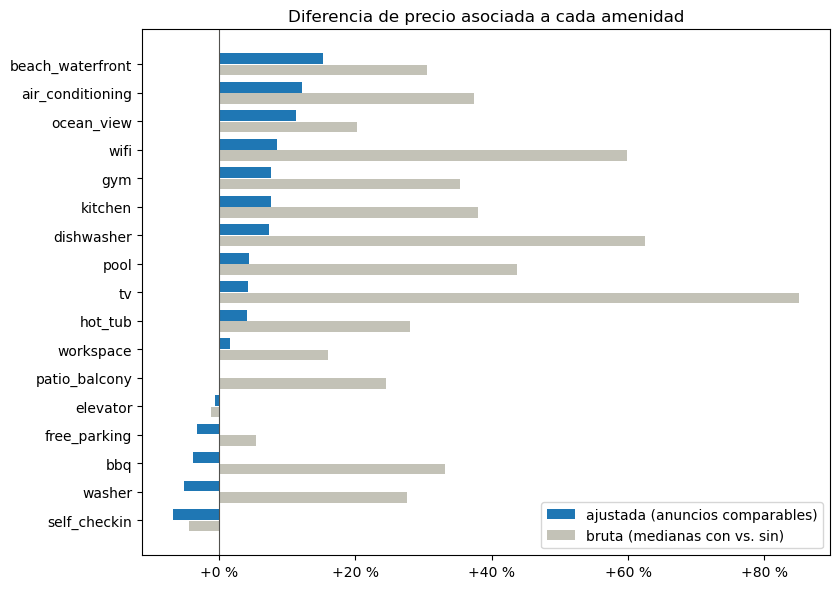

In [53]:
fig, ax = plt.subplots(figsize=(8.5, 6))
y = np.arange(len(tabla_am))
ax.barh(y + 0.2, tabla_am["dif. ajustada %"], height=0.38, label="ajustada (anuncios comparables)")
ax.barh(y - 0.2, tabla_am["dif. bruta %"], height=0.38, color="#c3c2b7", label="bruta (medianas con vs. sin)")
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(tabla_am.index)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.0f} %"))
ax.grid(axis="y", visible=False)
ax.set_title("Diferencia de precio asociada a cada amenidad")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Buscar realacion entre amenidades y precio y calificacion

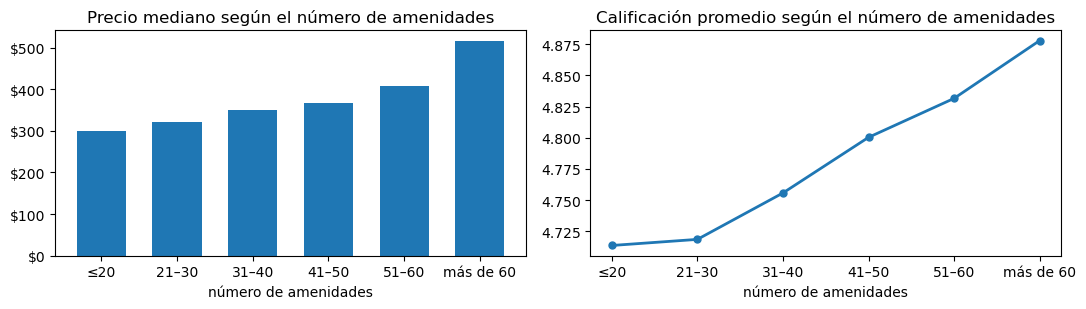

In [56]:
df["amen_bin"] = pd.cut(df["n_amenities"], [-1, 20, 30, 40, 50, 60, 200], labels=["≤20", "21–30", "31–40", "41–50", "51–60", "más de 60"])
g = df.groupby("amen_bin", observed=True).agg(precio=("price", "median"), calificacion=("review_scores_rating", "mean"), n=("price", "size"))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].bar(g.index.astype(str), g["precio"], width=0.65)
axes[0].yaxis.set_major_formatter(usd); axes[0].set_title("Precio mediano según el número de amenidades"); axes[0].grid(axis="x", visible=False)
con_res = df[df["has_reviews"] == 1].groupby("amen_bin", observed=True)["review_scores_rating"].mean()
axes[1].plot(con_res.index.astype(str), con_res.values, lw=2, marker="o", ms=5)
axes[1].set_title("Calificación promedio según el número de amenidades"); axes[1].set_xlabel("número de amenidades")
axes[0].set_xlabel("número de amenidades")
plt.tight_layout()
plt.show()

las diferecnias brutas exageran el efecto de casi todas las amenidades, porque viene acompañadas de inmuebles mas grandes y mejor ubicados. Tras controlar por esas caracteristicas las diferencias se reducen mucho

declarar mas amenidades se asocia con mayor precio 300 usd con 20 o mnes frente a 515 con mas de 60



Efecto de la fecha 

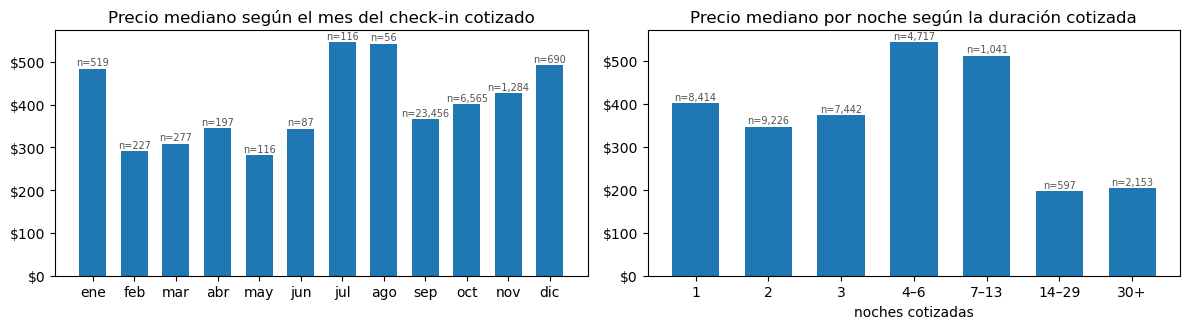

Cotizaciones con check-in en septiembre u octubre: 89%
Precio mediano por noche, estancia mínima < 30 noches: $385  |  >= 30 noches: $202


In [59]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
meses = df.groupby("quote_checkin_month")["price"].agg(["median", "size"])
nombres = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
axes[0].bar([nombres[m - 1] for m in meses.index], meses["median"], width=0.65)
for i, (v, n) in enumerate(zip(meses["median"], meses["size"])):
    axes[0].text(i, v + 8, f"n={n:,}", ha="center", fontsize=7, color="#52514e")
axes[0].yaxis.set_major_formatter(usd); axes[0].grid(axis="x", visible=False)
axes[0].set_title("Precio mediano según el mes del check-in cotizado")

df["noches_bin"] = pd.cut(df["quote_nights"], [0, 1, 2, 3, 6, 13, 29, 400], labels=["1", "2", "3", "4–6", "7–13", "14–29", "30+"])
noches = df.groupby("noches_bin", observed=True)["price"].agg(["median", "size"])
axes[1].bar(noches.index.astype(str), noches["median"], width=0.65)
for i, (v, n) in enumerate(zip(noches["median"], noches["size"])):
    axes[1].text(i, v + 8, f"n={n:,}", ha="center", fontsize=7, color="#52514e")
axes[1].yaxis.set_major_formatter(usd); axes[1].grid(axis="x", visible=False)
axes[1].set_xlabel("noches cotizadas"); axes[1].set_title("Precio mediano por noche según la duración cotizada")
plt.tight_layout()
plt.show()
print(f"Cotizaciones con check-in en septiembre u octubre: {df['quote_checkin_month'].isin([9, 10]).mean():.0%}")
print(f"Precio mediano por noche, estancia mínima < 30 noches: ${df.loc[df['long_stay']==0,'price'].median():,.0f}  |  >= 30 noches: ${df.loc[df['long_stay']==1,'price'].median():,.0f}")